# Online Retail II: revenue, retention and baskets with SQL (2009–2011)

**Ashhar Hussain** · ORCID [0009-0009-1568-9852](https://orcid.org/0009-0009-1568-9852)

Two years of transactions (1,067,371 invoice lines) from a UK-based online retailer of gifts and homeware, many of whose customers are wholesalers (Chen, Sain & Guo, 2012; UCI Machine Learning Repository). The analysis is written as SQL in DuckDB, with pandas only for plotting and the Excel export, so every number can be traced to a query.

**Questions a commercial team would ask**

1. How much of the raw data is usable, and how much does cleaning change revenue?
2. How do revenue, orders, order value and active customers move by month, and how did 2011 compare with 2010?
3. Of the customers acquired in a month, how many come back, and when do they stop?
4. How concentrated is revenue, and which customer segments deserve which action?
5. Which products are bought together often enough to bundle or cross-sell?

**Run.** Any CPU runtime, about 5 minutes (the first run converts the Excel file to Parquet). Output: figures and an Excel workbook in `outputs/`.

In [1]:
import io, json, time, zipfile, urllib.request
from pathlib import Path
import numpy as np, pandas as pd
import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

OUT = Path("outputs"); FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)
DATA = Path("data"); DATA.mkdir(exist_ok=True)
pq = DATA / "online_retail_ii.parquet"
if not pq.exists():
    z = DATA / "online_retail_ii.zip"
    if not z.exists():
        urllib.request.urlretrieve("https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip", z)
    t0 = time.time()
    xls = zipfile.ZipFile(z).read("online_retail_II.xlsx")
    sheets = pd.read_excel(io.BytesIO(xls), sheet_name=None, dtype={"Invoice": str, "StockCode": str, "Description": str, "Country": str})
    raw = pd.concat(sheets.values(), ignore_index=True)
    raw.columns = ["invoice", "stock_code", "description", "quantity", "invoice_ts", "price", "customer_id", "country"]
    raw["customer_id"] = raw["customer_id"].astype("Int64")
    raw.to_parquet(pq, index=False)
    print(f"converted {len(raw):,} rows from Excel in {time.time() - t0:.0f} s")

con = duckdb.connect()
con.execute(f"CREATE OR REPLACE VIEW raw AS SELECT * FROM read_parquet('{pq.as_posix()}')")
q = lambda sql: con.execute(sql).df()
q("SELECT COUNT(*) AS rows, COUNT(DISTINCT invoice) AS invoices, COUNT(DISTINCT customer_id) AS customers, "
  "MIN(invoice_ts) AS first_ts, MAX(invoice_ts) AS last_ts FROM raw")

,rows,invoices,customers,first_ts,last_ts
0,1067371,53628,5942,2009-12-01 07:45:00,2011-12-09 12:50:00


## 1. Data quality audit

Each rule is a query, so the audit doubles as documentation. Cancellations have invoice numbers starting with "C"; some stock codes are not products (postage, manual adjustments, bank charges, Amazon fees, samples); some lines have no customer.

In [2]:
NON_PRODUCT = "('POST','DOT','M','C2','CRUK','D','BANK CHARGES','PADS','ADJUST','ADJUST2','AMAZONFEE','S','B','TEST001','TEST002','GIFT')"
audit = q(f"""
SELECT
  COUNT(*)                                                         AS all_lines,
  SUM(CASE WHEN invoice LIKE 'C%' THEN 1 ELSE 0 END)               AS cancellation_lines,
  SUM(CASE WHEN customer_id IS NULL THEN 1 ELSE 0 END)             AS no_customer_id,
  SUM(CASE WHEN quantity <= 0 AND invoice NOT LIKE 'C%' THEN 1 ELSE 0 END) AS non_positive_qty_not_cancelled,
  SUM(CASE WHEN price <= 0 THEN 1 ELSE 0 END)                      AS zero_or_negative_price,
  SUM(CASE WHEN upper(stock_code) IN {NON_PRODUCT} OR stock_code ILIKE 'gift_%' THEN 1 ELSE 0 END) AS non_product_codes,
  COUNT(*) - COUNT(DISTINCT (invoice, stock_code, description, quantity, invoice_ts, price, customer_id, country)) AS exact_duplicates
FROM raw""")
display(audit.T.rename(columns={0: "lines"}))

con.execute(f"""
CREATE OR REPLACE TABLE sales AS
SELECT DISTINCT invoice, stock_code, trim(description) AS description, quantity, invoice_ts, price,
       customer_id, country, quantity * price AS revenue,
       date_trunc('month', invoice_ts)::DATE AS month
FROM raw
WHERE invoice NOT LIKE 'C%' AND quantity > 0 AND price > 0
  AND upper(stock_code) NOT IN {NON_PRODUCT} AND NOT stock_code ILIKE 'gift_%'
""")
con.execute("CREATE OR REPLACE TABLE known AS SELECT * FROM sales WHERE customer_id IS NOT NULL")
effect = q("""
SELECT 'raw (all lines)' AS stage, SUM(quantity * price) AS revenue, COUNT(*) AS lines FROM raw
UNION ALL SELECT 'clean sales', SUM(revenue), COUNT(*) FROM sales
UNION ALL SELECT 'clean sales with a customer id', SUM(revenue), COUNT(*) FROM known
""")
cancel = q("SELECT -SUM(quantity * price) AS cancelled_value FROM raw WHERE invoice LIKE 'C%'").iloc[0, 0]
display(effect.style.format({"revenue": "£{:,.0f}", "lines": "{:,}"}))
print(f"value of cancelled lines: £{cancel:,.0f}")

,lines
all_lines,1067371.0
cancellation_lines,19494.0
no_customer_id,243007.0
non_positive_qty_not_cancelled,3457.0
zero_or_negative_price,6207.0
non_product_codes,5931.0
exact_duplicates,34335.0


,stage,revenue,lines
0,raw (all lines),"£19,287,251","1,067,371"
1,clean sales,"£19,643,862","1,003,340"
2,clean sales with a customer id,"£17,068,583","776,579"


value of cancelled lines: £1,526,668


Customer-level analyses (retention, RFM, concentration) use only lines with a customer id; revenue trends use all clean sales. The share of revenue without a customer id is reported, because dropping it silently would understate the business.

## 2. Monthly KPIs and year-on-year growth

December 2011 is cut off on the 9th, so it is excluded from trend charts and growth figures.

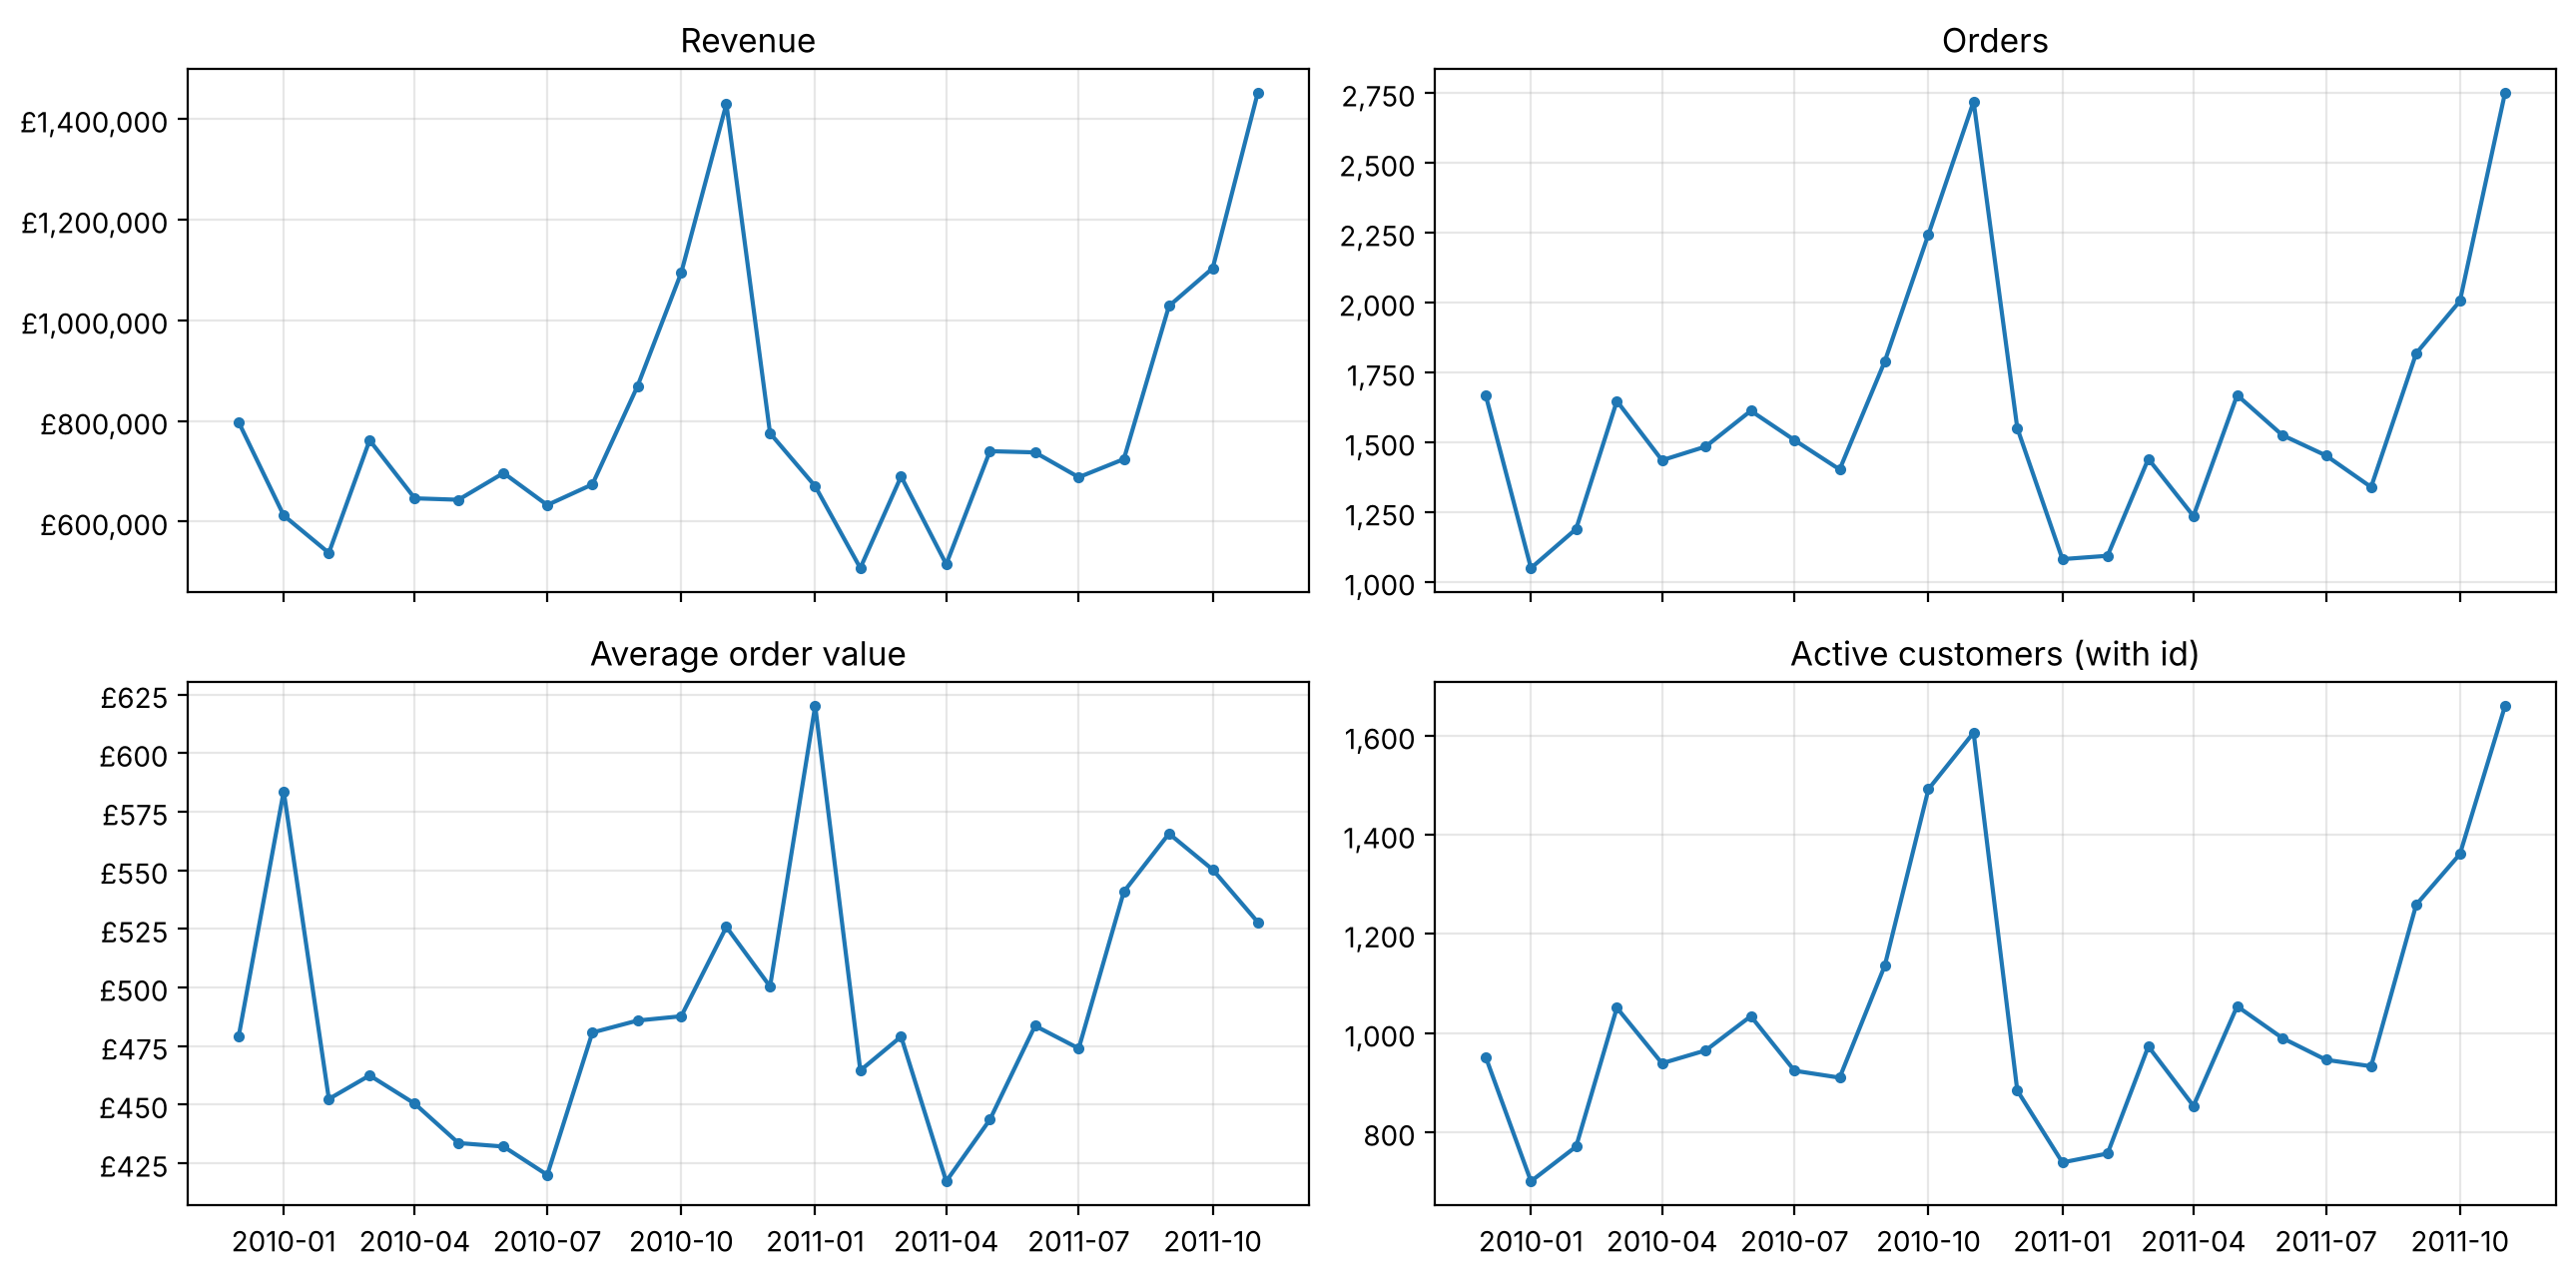

,month,revenue_2010,revenue_2011,revenue_growth,order_growth,customer_growth
0,Jan,"£612,297","£670,380",+9.5%,+3.1%,+5.4%
1,Feb,"£537,910","£507,800",-5.6%,-8.1%,-1.8%
2,Mar,"£761,706","£689,834",-9.4%,-12.6%,-7.4%
3,Apr,"£646,341","£515,378",-20.3%,-13.9%,-9.2%
4,May,"£643,492","£739,953",+15.0%,+12.4%,+9.2%
5,Jun,"£696,583","£737,559",+5.9%,-5.4%,-4.3%
6,Jul,"£632,994","£688,219",+8.7%,-3.6%,+2.4%
7,Aug,"£674,038","£724,217",+7.4%,-4.5%,+2.5%
8,Sep,"£869,243","£1,028,320",+18.3%,+1.6%,+10.8%
9,Oct,"£1,094,436","£1,103,314",+0.8%,-10.7%,-8.8%


January–November revenue, 2011 vs 2010: +3.0%


In [3]:
kpi = q("""
SELECT month,
       SUM(revenue)                         AS revenue,
       COUNT(DISTINCT invoice)              AS orders,
       SUM(revenue) / COUNT(DISTINCT invoice) AS avg_order_value,
       COUNT(DISTINCT customer_id)          AS active_customers,
       SUM(CASE WHEN customer_id IS NULL THEN revenue ELSE 0 END) / SUM(revenue) AS share_no_customer_id
FROM sales WHERE month < DATE '2011-12-01'
GROUP BY month ORDER BY month""")
kpi["month"] = pd.to_datetime(kpi["month"])
yoy = q("""
WITH m AS (SELECT month, SUM(revenue) AS revenue, COUNT(DISTINCT invoice) AS orders, COUNT(DISTINCT customer_id) AS customers
           FROM sales WHERE month BETWEEN DATE '2010-01-01' AND DATE '2011-11-01' GROUP BY month)
SELECT strftime(a.month, '%b') AS month, a.revenue AS revenue_2010, b.revenue AS revenue_2011,
       b.revenue / a.revenue - 1 AS revenue_growth, b.orders / a.orders - 1 AS order_growth,
       b.customers / a.customers - 1 AS customer_growth
FROM m a JOIN m b ON b.month = a.month + INTERVAL 1 YEAR ORDER BY a.month""")
ytd = q("""SELECT SUM(CASE WHEN year(month)=2011 THEN revenue END) / SUM(CASE WHEN year(month)=2010 THEN revenue END) - 1 AS ytd_growth
          FROM sales WHERE month BETWEEN DATE '2010-01-01' AND DATE '2011-11-01' AND month(month) <= 11""").iloc[0, 0]

fig, ax = plt.subplots(2, 2, figsize=(13, 6.5), sharex=True)
for a, col, title, fmt in ((ax[0, 0], "revenue", "Revenue", "£{x:,.0f}"), (ax[0, 1], "orders", "Orders", "{x:,.0f}"),
                           (ax[1, 0], "avg_order_value", "Average order value", "£{x:,.0f}"), (ax[1, 1], "active_customers", "Active customers (with id)", "{x:,.0f}")):
    a.plot(kpi.month, kpi[col], marker="o", ms=3)
    a.set_title(title); a.yaxis.set_major_formatter(mtick.StrMethodFormatter(fmt)); a.grid(alpha=0.3)
plt.tight_layout(); fig.savefig(FIG / "monthly_kpis.png", dpi=130); plt.show()
display(yoy.style.format({"revenue_2010": "£{:,.0f}", "revenue_2011": "£{:,.0f}", "revenue_growth": "{:+.1%}",
                          "order_growth": "{:+.1%}", "customer_growth": "{:+.1%}"}))
print(f"January–November revenue, 2011 vs 2010: {ytd:+.1%}")

## 3. Acquisition cohorts and retention

A customer's cohort is the month of their first purchase (from December 2009). Retention in month *k* is the share of the cohort that bought again *k* months later.

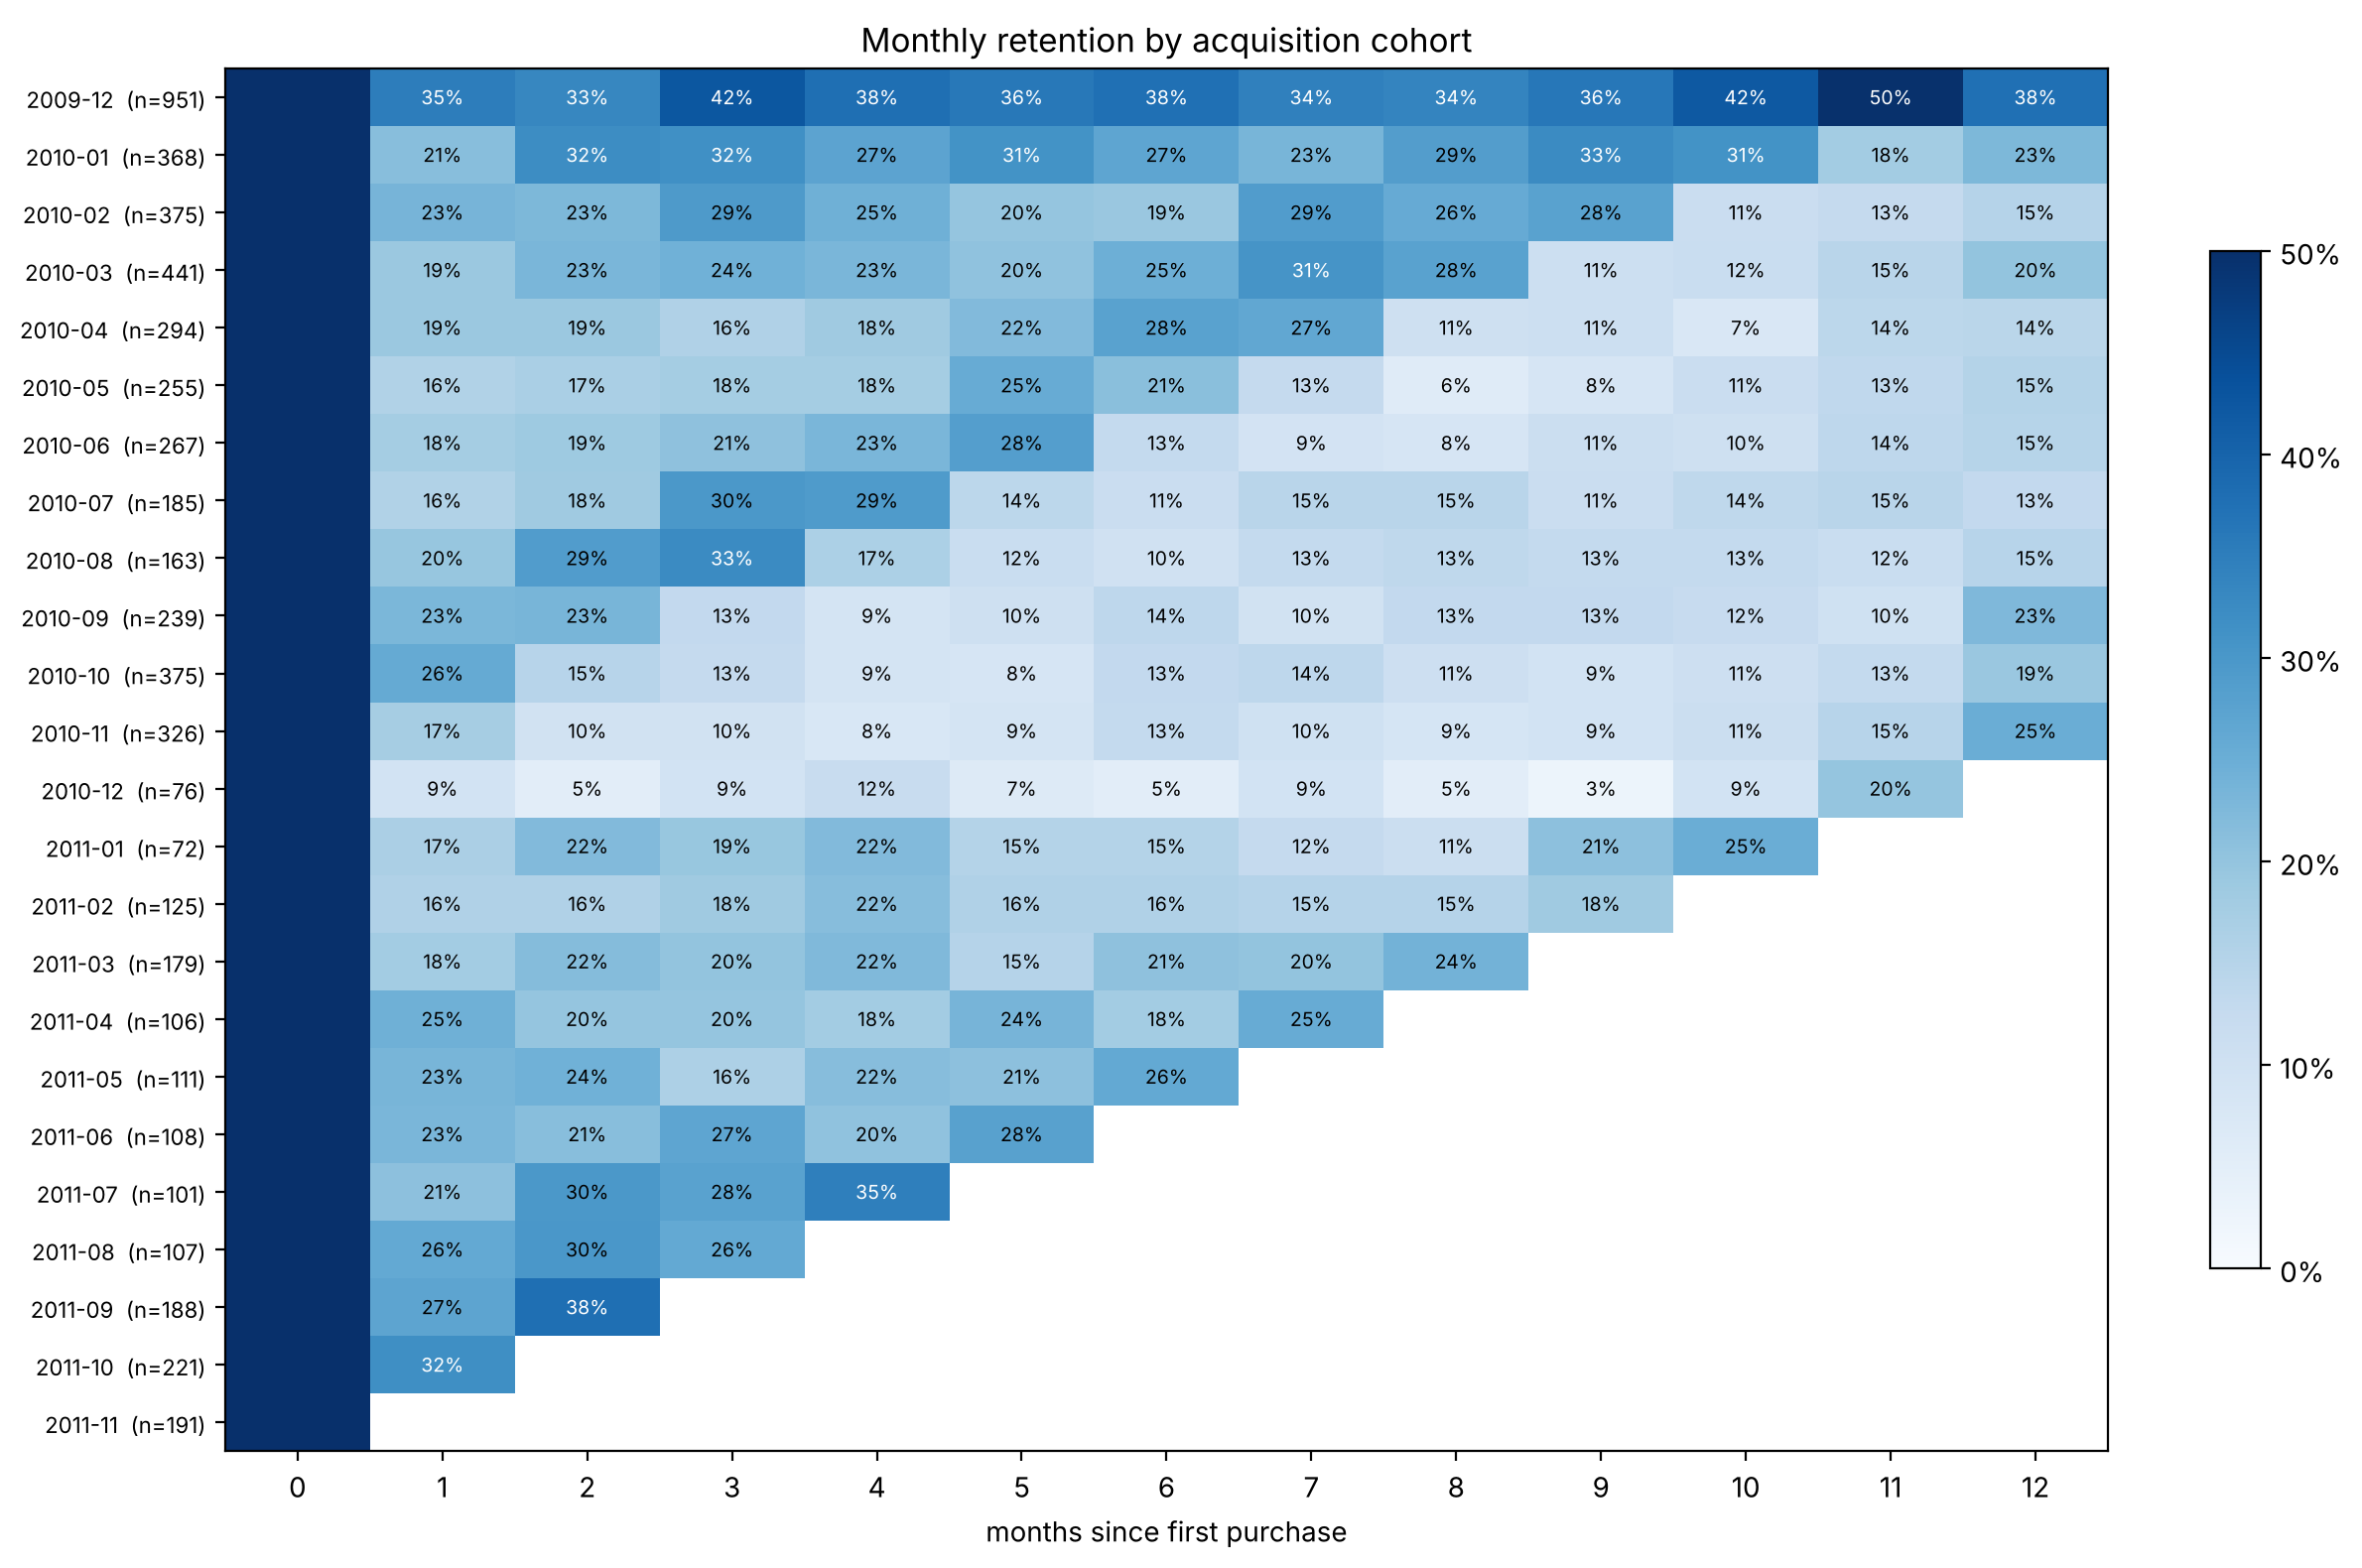

Month-1 retention: median 20.8% across cohorts (first cohort 35.0%); month-3: median 20.1%; month-12 for cohorts that have reached it: median 17.2%


In [4]:
cohorts = q("""
WITH firsts AS (SELECT customer_id, MIN(month) AS cohort FROM known GROUP BY customer_id),
     activity AS (SELECT DISTINCT k.customer_id, f.cohort, date_diff('month', f.cohort, k.month) AS k
                  FROM known k JOIN firsts f USING (customer_id) WHERE k.month < DATE '2011-12-01')
SELECT cohort, k, COUNT(*) AS customers FROM activity GROUP BY cohort, k ORDER BY cohort, k""")
mat = cohorts.pivot(index="cohort", columns="k", values="customers")
ret = mat.div(mat[0], axis=0)
ret.index = pd.to_datetime(ret.index).strftime("%Y-%m")
show = ret.iloc[:, :13]
fig, ax = plt.subplots(figsize=(12, 8))
im = ax.imshow(show.values, cmap="Blues", vmin=0, vmax=0.5, aspect="auto")
ax.set_xticks(range(show.shape[1])); ax.set_xticklabels(show.columns)
ax.set_yticks(range(len(show))); ax.set_yticklabels([f"{i}  (n={int(n)})" for i, n in zip(show.index, mat[0])], fontsize=8)
for i in range(show.shape[0]):
    for j in range(1, show.shape[1]):
        v = show.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7, color="white" if v > 0.3 else "black")
ax.set_xlabel("months since first purchase"); ax.set_title("Monthly retention by acquisition cohort")
plt.colorbar(im, fraction=0.025, format=mtick.PercentFormatter(1.0)); plt.tight_layout(); fig.savefig(FIG / "cohort_retention.png", dpi=130); plt.show()

m1 = ret[1].dropna(); m3 = ret[3].dropna(); m12 = ret[12].dropna() if 12 in ret else pd.Series(dtype=float)
first = ret.index[0]
print(f"Month-1 retention: median {m1.median():.1%} across cohorts (first cohort {ret.loc[first, 1]:.1%}); "
      f"month-3: median {m3.median():.1%}; month-12 for cohorts that have reached it: median {m12.median():.1%}")

## 4. Concentration and RFM segments

Recency, frequency and monetary value are scored 1–5 by quintile over the 12 months to 9 December 2011 (`NTILE` in SQL), and mapped to segments with simple, explainable rules.

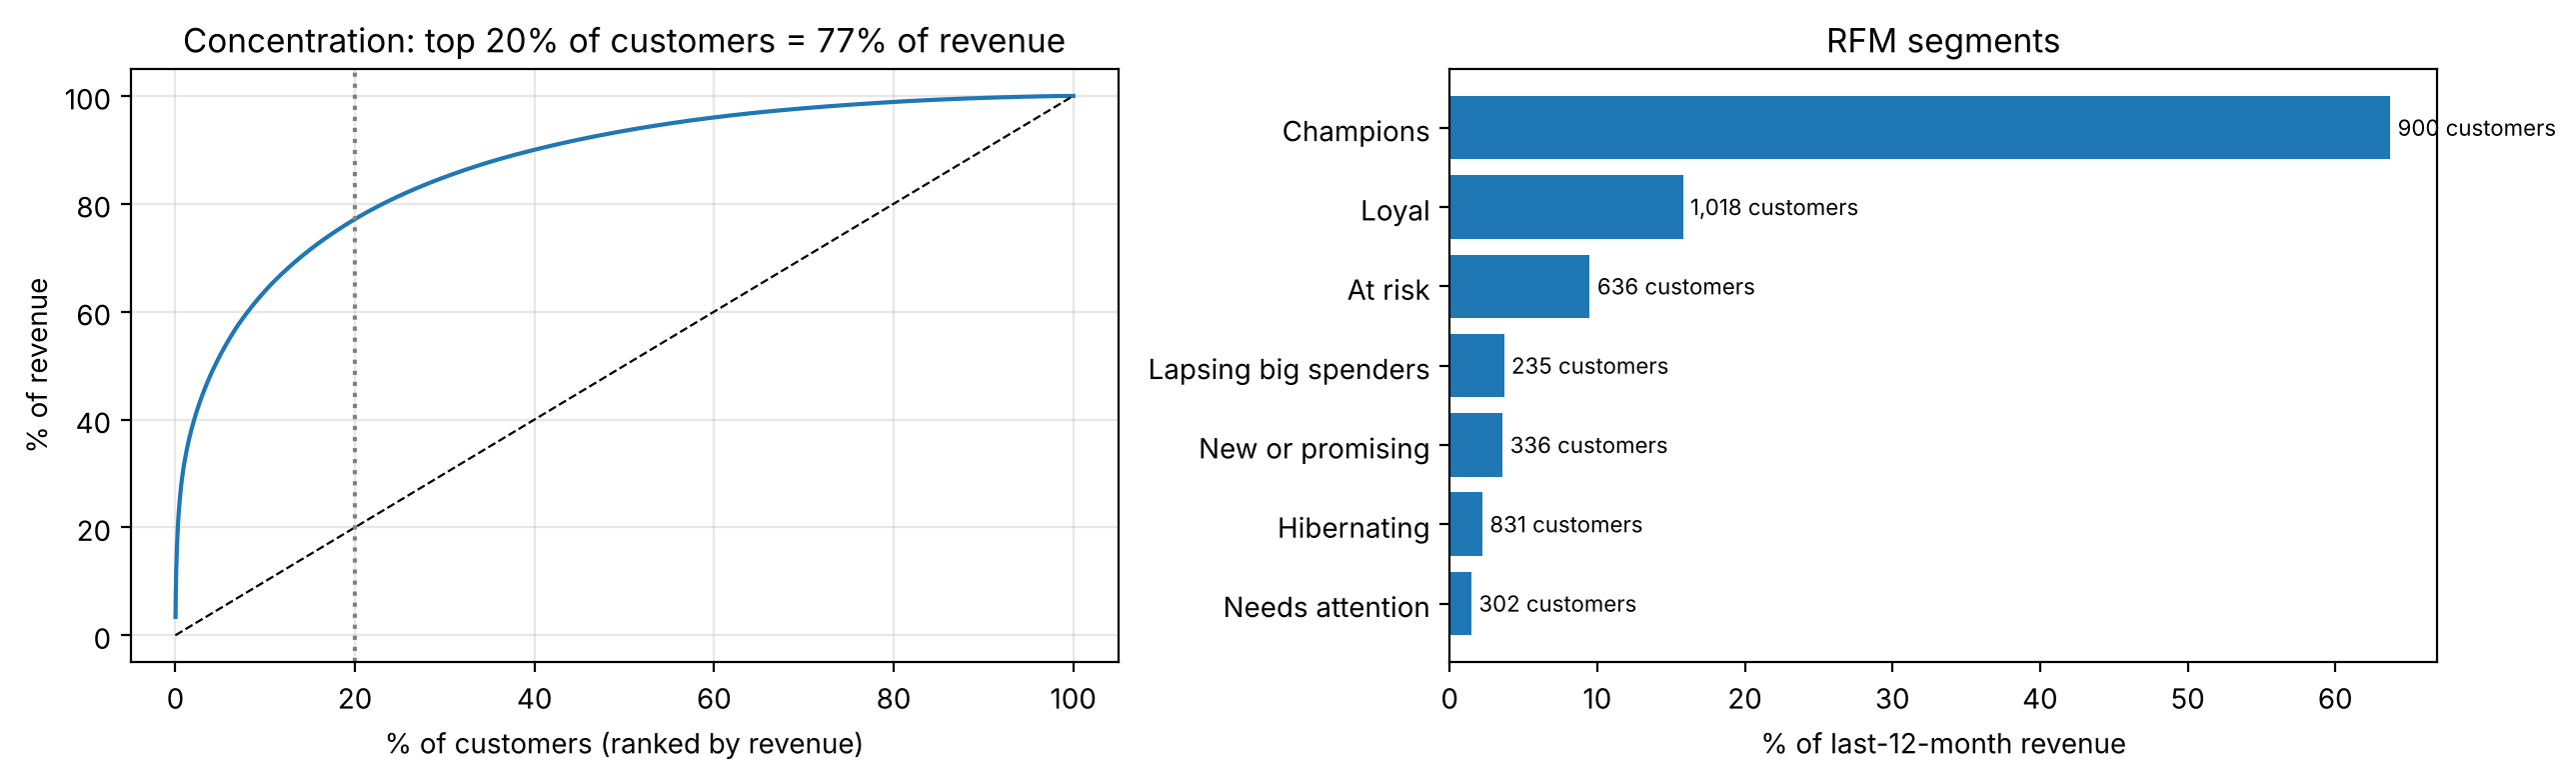

,customers,revenue,median_recency_days,median_orders,revenue_share,suggested action
segment,,,,,,
Champions,900,"£5,358,608",10,7,63.7%,"retain: early access, account manager"
Loyal,1018,"£1,328,770",34,3,15.8%,"upsell bundles, loyalty tier"
At risk,636,"£798,967",114,3,9.5%,win-back offer before they lapse
Lapsing big spenders,235,"£309,637",212,1,3.7%,personal outreach
New or promising,336,"£302,236",19,1,3.6%,second-order incentive within 30 days
Hibernating,831,"£186,636",227,1,2.2%,low-cost reactivation email only
Needs attention,302,"£124,093",52,1,1.5%,test targeted offers


In [5]:
pareto = q("""
WITH c AS (SELECT customer_id, SUM(revenue) AS rev FROM known GROUP BY customer_id),
     r AS (SELECT rev, ROW_NUMBER() OVER (ORDER BY rev DESC) AS rk, COUNT(*) OVER () AS n, SUM(rev) OVER () AS tot FROM c)
SELECT rk / n AS customer_share, SUM(rev) OVER (ORDER BY rk) / tot AS revenue_share FROM r ORDER BY rk""")
top20 = pareto.loc[pareto.customer_share <= 0.2, "revenue_share"].max()
top1 = pareto.loc[pareto.customer_share <= 0.01, "revenue_share"].max()

rfm = q("""
WITH ref AS (SELECT MAX(invoice_ts) + INTERVAL 1 DAY AS as_of_ts FROM known),
     base AS (SELECT customer_id, date_diff('day', MAX(invoice_ts), (SELECT as_of_ts FROM ref)) AS recency_days,
                     COUNT(DISTINCT invoice) AS frequency, SUM(revenue) AS monetary
              FROM known WHERE invoice_ts >= (SELECT as_of_ts FROM ref) - INTERVAL 365 DAY GROUP BY customer_id),
     scored AS (SELECT *, 6 - NTILE(5) OVER (ORDER BY recency_days) AS r, NTILE(5) OVER (ORDER BY frequency) AS f,
                          NTILE(5) OVER (ORDER BY monetary) AS m FROM base)
SELECT *, CASE
  WHEN r >= 4 AND f >= 4 AND m >= 4 THEN 'Champions'
  WHEN r >= 3 AND f >= 3              THEN 'Loyal'
  WHEN r >= 4 AND f <= 2              THEN 'New or promising'
  WHEN r <= 2 AND f >= 3              THEN 'At risk'
  WHEN r <= 2 AND f <= 2 AND m >= 3   THEN 'Lapsing big spenders'
  WHEN r <= 2                          THEN 'Hibernating'
  ELSE 'Needs attention' END AS segment
FROM scored""")
seg = rfm.groupby("segment").agg(customers=("customer_id", "size"), revenue=("monetary", "sum"),
                                 median_recency_days=("recency_days", "median"), median_orders=("frequency", "median"))
seg["revenue_share"] = seg.revenue / seg.revenue.sum()
seg = seg.sort_values("revenue", ascending=False)
ACTIONS = {"Champions": "retain: early access, account manager", "Loyal": "upsell bundles, loyalty tier",
           "New or promising": "second-order incentive within 30 days", "At risk": "win-back offer before they lapse",
           "Lapsing big spenders": "personal outreach", "Hibernating": "low-cost reactivation email only",
           "Needs attention": "test targeted offers"}
seg["suggested action"] = seg.index.map(ACTIONS)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(100 * pareto.customer_share, 100 * pareto.revenue_share); ax[0].plot([0, 100], [0, 100], "k--", lw=0.8)
ax[0].axvline(20, c="gray", ls=":"); ax[0].set_xlabel("% of customers (ranked by revenue)"); ax[0].set_ylabel("% of revenue")
ax[0].set_title(f"Concentration: top 20% of customers = {top20:.0%} of revenue"); ax[0].grid(alpha=0.3)
ax[1].barh(seg.index[::-1], seg.revenue_share[::-1] * 100, color="#1f77b4")
for i, (n, s) in enumerate(zip(seg.customers[::-1], seg.revenue_share[::-1])):
    ax[1].text(s * 100 + 0.5, i, f"{n:,} customers", va="center", fontsize=8)
ax[1].set_xlabel("% of last-12-month revenue"); ax[1].set_title("RFM segments")
plt.tight_layout(); fig.savefig(FIG / "concentration_rfm.png", dpi=130); plt.show()
display(seg.style.format({"revenue": "£{:,.0f}", "revenue_share": "{:.1%}", "median_recency_days": "{:.0f}", "median_orders": "{:.0f}"}))

## 5. Market basket: which products go together?

Pairs of products in the same invoice, for UK orders in 2011, among products that appear in at least 300 orders. Support is the share of orders containing both, confidence is P(B | A) and lift compares the pair's frequency with what independence would give. Pairs are computed with a self-join in SQL.

In [6]:
pairs = q("""
WITH b AS (SELECT DISTINCT invoice, stock_code FROM sales WHERE country = 'United Kingdom' AND year(invoice_ts) = 2011),
     n AS (SELECT COUNT(DISTINCT invoice) AS orders FROM b),
     freq AS (SELECT stock_code, COUNT(*) AS cnt FROM b GROUP BY stock_code HAVING COUNT(*) >= 300),
     bb AS (SELECT b.* FROM b JOIN freq USING (stock_code)),
     p AS (SELECT x.stock_code AS a, y.stock_code AS c, COUNT(*) AS both_cnt
           FROM bb x JOIN bb y ON x.invoice = y.invoice AND x.stock_code < y.stock_code GROUP BY 1, 2 HAVING COUNT(*) >= 150)
SELECT p.a, p.c, p.both_cnt, p.both_cnt / n.orders AS support,
       p.both_cnt / fa.cnt AS confidence_a_to_c, p.both_cnt / fc.cnt AS confidence_c_to_a,
       (p.both_cnt * n.orders) / (fa.cnt * fc.cnt) AS lift
FROM p, n, freq fa, freq fc WHERE fa.stock_code = p.a AND fc.stock_code = p.c
ORDER BY lift DESC""")
names = q("SELECT stock_code, arg_max(description, invoice_ts) AS name FROM sales GROUP BY stock_code").set_index("stock_code")["name"]
pairs["product_a"] = pairs.a.map(names); pairs["product_c"] = pairs.c.map(names)
top_pairs = pairs.head(15)[["product_a", "product_c", "both_cnt", "support", "confidence_a_to_c", "confidence_c_to_a", "lift"]]
display(top_pairs.style.format({"support": "{:.2%}", "confidence_a_to_c": "{:.0%}", "confidence_c_to_a": "{:.0%}", "lift": "{:.1f}"}))
print(f"{len(pairs):,} product pairs pass the thresholds; median lift {pairs.lift.median():.1f}")

,product_a,product_c,both_cnt,support,confidence_a_to_c,confidence_c_to_a,lift
0,POPPY'S PLAYHOUSE BEDROOM,POPPY'S PLAYHOUSE KITCHEN,219,1.33%,72%,70%,37.9
1,REGENCY TEA PLATE ROSES,REGENCY TEA PLATE GREEN,281,1.71%,74%,84%,36.1
2,BLUE HAPPY BIRTHDAY BUNTING,PINK HAPPY BIRTHDAY BUNTING,217,1.32%,66%,64%,32.3
3,SET OF 6 SNACK LOAF BAKING CASES,SET OF 6 TEA TIME BAKING CASES,175,1.06%,58%,54%,29.4
4,BLUE SPOT CERAMIC DRAWER KNOB,RED SPOT CERAMIC DRAWER KNOB,177,1.08%,55%,57%,29.1
5,RED STRIPE CERAMIC DRAWER KNOB,RED SPOT CERAMIC DRAWER KNOB,199,1.21%,54%,64%,28.9
6,RED SPOT CERAMIC DRAWER KNOB,WHITE SPOT RED CERAMIC DRAWER KNOB,181,1.10%,59%,54%,28.9
7,BLUE SPOT CERAMIC DRAWER KNOB,WHITE SPOT BLUE CERAMIC DRAWER KNOB,172,1.04%,53%,56%,28.6
8,SET OF 6 SNACK LOAF BAKING CASES,SET OF 12 MINI LOAF BAKING CASES,202,1.23%,66%,53%,28.5
9,ROLL WRAP VINTAGE CHRISTMAS,ROLL WRAP 50'S CHRISTMAS,179,1.09%,57%,54%,28.2


1,378 product pairs pass the thresholds; median lift 4.5


## 6. Geography

In [7]:
geo = q("""
SELECT CASE WHEN country = 'United Kingdom' THEN 'United Kingdom' ELSE country END AS country,
       SUM(revenue) AS revenue, COUNT(DISTINCT customer_id) AS customers,
       SUM(revenue) / COUNT(DISTINCT invoice) AS avg_order_value
FROM sales GROUP BY 1 ORDER BY revenue DESC""")
geo["revenue_share"] = geo.revenue / geo.revenue.sum()
uk_share = float(geo.loc[geo.country == "United Kingdom", "revenue_share"].iloc[0])
display(geo.head(10).style.format({"revenue": "£{:,.0f}", "avg_order_value": "£{:,.0f}", "revenue_share": "{:.1%}"}))

,country,revenue,customers,avg_order_value,revenue_share
0,United Kingdom,"£16,801,019",5334,£464,85.5%
1,EIRE,"£623,414",3,"£1,073",3.2%
2,Netherlands,"£549,773",22,"£2,545",2.8%
3,Germany,"£383,289",107,£509,2.0%
4,France,"£311,090",93,£520,1.6%
5,Australia,"£167,800",15,"£1,885",0.9%
6,Spain,"£97,767",38,£679,0.5%
7,Switzerland,"£94,025",22,"£1,106",0.5%
8,Sweden,"£86,319",19,£872,0.4%
9,Denmark,"£67,423",12,"£1,605",0.3%


## Summary for the commercial team, and the Excel pack

In [8]:
from IPython.display import Markdown
peak = kpi.loc[kpi.revenue.idxmax()]
champ = seg.loc["Champions"] if "Champions" in seg.index else None
risk = seg.loc["At risk"] if "At risk" in seg.index else None
p0 = top_pairs.iloc[0]
md = "\n\n".join([
    f"**Data.** {int(audit.all_lines.iloc[0]):,} raw lines; after removing cancellations, non-product codes, non-positive quantities and prices and "
    f"{int(audit.exact_duplicates.iloc[0]):,} exact duplicates, {int(effect.lines.iloc[1]):,} sales lines remain worth £{effect.revenue.iloc[1]:,.0f}. "
    f"Cancelled lines were worth £{cancel:,.0f}. {1 - effect.revenue.iloc[2] / effect.revenue.iloc[1]:.1%} of clean revenue has no customer id.",
    f"**Trend.** Revenue peaks in {peak.month:%B %Y} (£{peak.revenue:,.0f}); January–November 2011 revenue was {ytd:+.1%} on the same months of 2010. "
    f"The year is strongly seasonal, with the autumn ramp-up starting in September.",
    f"**Retention.** Median month-1 retention across cohorts is {m1.median():.1%} and month-3 {m3.median():.1%}; the first cohort (December 2009, which "
    f"includes long-standing customers) retains far better than later ones, so blended figures overstate how sticky new customers are.",
    f"**Concentration.** The top 20% of customers bring {top20:.0%} of revenue and the top 1% bring {top1:.0%}. "
    + (f"Champions are {int(champ.customers):,} customers with {champ.revenue_share:.0%} of last-year revenue; " if champ is not None else "")
    + (f"{int(risk.customers):,} customers are 'at risk' (frequent buyers who have gone quiet), holding {risk.revenue_share:.0%}." if risk is not None else ""),
    f"**Baskets.** The strongest pair is '{p0.product_a}' with '{p0.product_c}' (lift {p0.lift:.1f}, bought together in {int(p0.both_cnt):,} UK orders in 2011): "
    f"colour or design variants of the same item dominate the top pairs, which suggests bundles and 'complete the set' prompts.",
    f"**Geography.** The UK is {uk_share:.0%} of revenue; the largest international markets have higher average order values, consistent with wholesale buyers.",
])
(OUT / "summary.md").write_text(md)
with pd.ExcelWriter(OUT / "online_retail_analysis.xlsx", engine="openpyxl") as xw:
    kpi.assign(month=kpi.month.dt.strftime("%Y-%m")).to_excel(xw, sheet_name="Monthly KPIs", index=False)
    yoy.to_excel(xw, sheet_name="YoY 2011 vs 2010", index=False)
    ret.round(4).to_excel(xw, sheet_name="Cohort retention")
    seg.reset_index().to_excel(xw, sheet_name="RFM segments", index=False)
    rfm.to_excel(xw, sheet_name="RFM by customer", index=False)
    top_pairs.to_excel(xw, sheet_name="Product pairs", index=False)
    geo.to_excel(xw, sheet_name="Countries", index=False)
json.dump(dict(raw_lines=int(audit.all_lines.iloc[0]), clean_lines=int(effect.lines.iloc[1]), clean_revenue=float(effect.revenue.iloc[1]),
               ytd_growth=float(ytd), m1_retention_median=float(m1.median()), m3_retention_median=float(m3.median()),
               top20_share=float(top20), top1_share=float(top1), n_pairs=int(len(pairs)), uk_share=uk_share),
          open(OUT / "summary.json", "w"), indent=2)
display(Markdown(md))
print("Excel pack written: outputs/online_retail_analysis.xlsx (7 sheets)")

**Data.** 1,067,371 raw lines; after removing cancellations, non-product codes, non-positive quantities and prices and 34,335 exact duplicates, 1,003,340 sales lines remain worth £19,643,862. Cancelled lines were worth £1,526,668. 13.1% of clean revenue has no customer id.

**Trend.** Revenue peaks in November 2011 (£1,452,116); January–November 2011 revenue was +3.0% on the same months of 2010. The year is strongly seasonal, with the autumn ramp-up starting in September.

**Retention.** Median month-1 retention across cohorts is 20.8% and month-3 20.1%; the first cohort (December 2009, which includes long-standing customers) retains far better than later ones, so blended figures overstate how sticky new customers are.

**Concentration.** The top 20% of customers bring 77% of revenue and the top 1% bring 32%. Champions are 900 customers with 64% of last-year revenue; 636 customers are 'at risk' (frequent buyers who have gone quiet), holding 10%.

**Baskets.** The strongest pair is 'POPPY'S PLAYHOUSE BEDROOM' with 'POPPY'S PLAYHOUSE KITCHEN' (lift 37.9, bought together in 219 UK orders in 2011): colour or design variants of the same item dominate the top pairs, which suggests bundles and 'complete the set' prompts.

**Geography.** The UK is 86% of revenue; the largest international markets have higher average order values, consistent with wholesale buyers.

Excel pack written: outputs/online_retail_analysis.xlsx (7 sheets)


### Notes and limitations

* Revenue is quantity × unit price before cancellations are netted; cancelled value is reported separately rather than matched line by line to the original orders.
* Retention counts any purchase as a return; wholesalers order on their own cycles, so month-to-month retention understates loyalty for quarterly buyers.
* RFM rules are deliberately simple and explainable; a predictive churn or CLV model would be the next step.
* Basket lift for colour variants of one product is real but trivial; for merchandising, pairs across product families are more useful and can be filtered by description.

**Data:** Chen, D. (2012). *Online Retail II* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5CG6D